In [24]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats

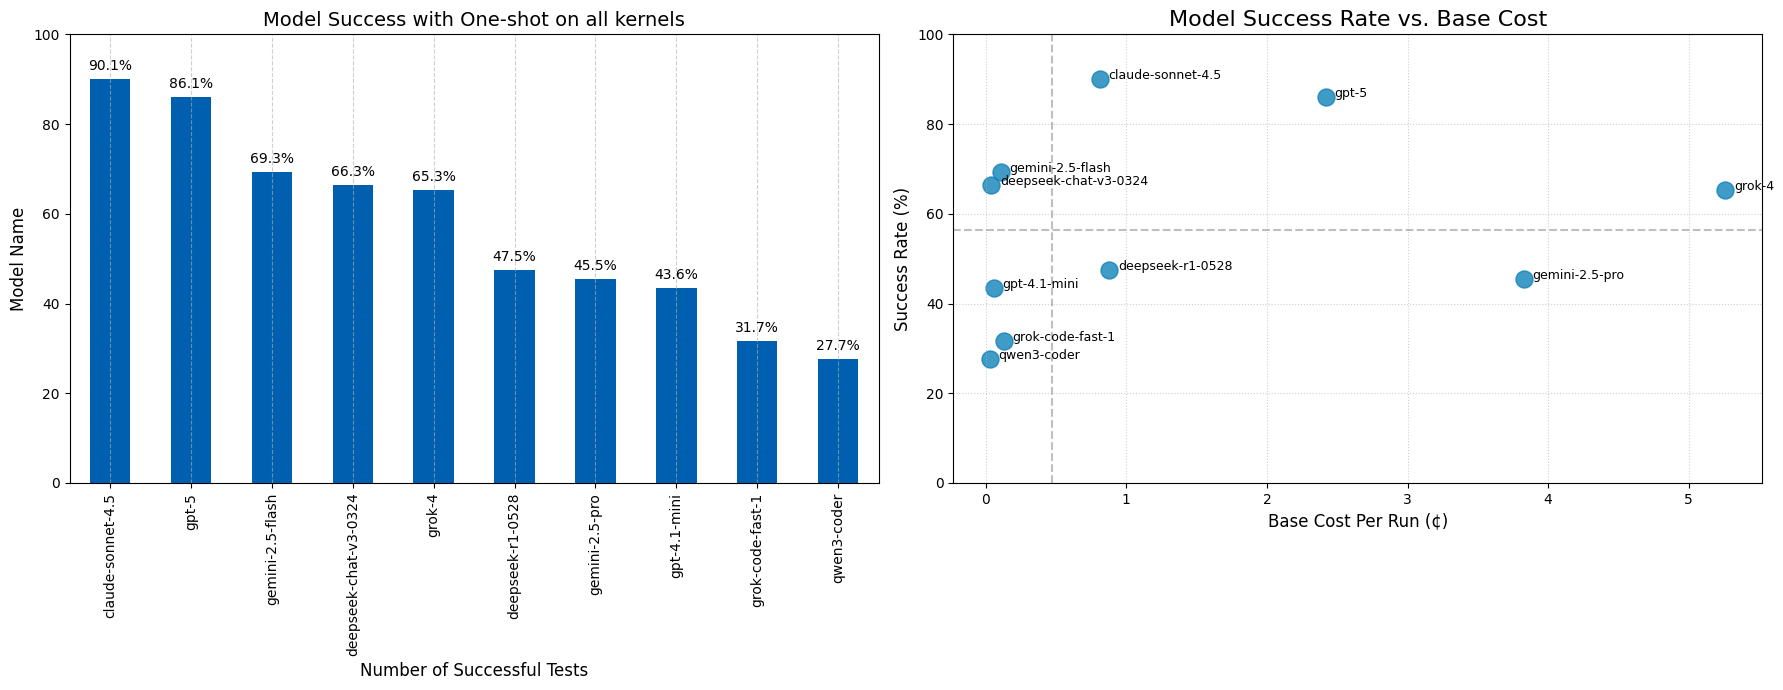

In [25]:
# Load data
df_oneshot_vitis_cheap = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_norag.csv')
df_oneshot_vitis_expensive = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_norag.csv')
# Calculate and add a column saying success for synthesis
df_oneshot_vitis_comb = pd.concat([df_oneshot_vitis_cheap, df_oneshot_vitis_expensive], ignore_index=True)
df_oneshot_vitis_comb['latency'] = pd.to_numeric(df_oneshot_vitis_comb['latency'], errors='coerce')
df_oneshot_vitis_comb['Success'] = ((df_oneshot_vitis_comb['latency'].notna()) & (df_oneshot_vitis_comb['latency'] > 5)).astype(int)
df_oneshot_vitis_comb['model'] = df_oneshot_vitis_comb['model'].str.split('/').str[-1]

# Calculate the Successes and Group by model
success_counts_unsorted = df_oneshot_vitis_comb.groupby('model')['Success'].sum()
success_counts = df_oneshot_vitis_comb.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag = (success_counts / total_tests) * 100
success_rates_unsorted = (success_counts_unsorted / total_tests) * 100

# print(success_rates_norag)

######################################## MAKE BAR CHART ###################################################
fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Generate the Bar chart
# plt.figure(figsize=(10,6))

success_rates_norag.plot(kind='bar', color="#0060af", ax=axs[0])
for index, value in enumerate(success_rates_norag):
    label = f"{value:.1f}%"
    axs[0].text(index, value+2, label, ha='center') # f' {value}' adds space after the bar
# Formatting and labels
axs[0].set_title(f'Model Success with One-shot on all kernels', fontsize=14)
axs[0].set_xlabel('Number of Successful Tests', fontsize=12)
axs[0].set_ylim(0,100)
axs[0].set_ylabel('Model Name', fontsize=12)
# Invert y-axis to put the highest performing model at the top
# axs[0].invert_yaxis() 
axs[0].grid(axis='x', linestyle='--', alpha=0.6) # Add light grid lines for readability
# plt.tight_layout()

#################################################### SCATTER PLOT CHART #################################################
model_costs_data = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.11, 0.04, 0.88, 0.06, 0.13, 0.03, 2.42, 5.26, 3.83, 0.81]
}

costs_df = pd.DataFrame(model_costs_data).set_index('Model')

combined_df = pd.DataFrame({
    'Success_Rate': success_rates_norag,
    'Cost': costs_df['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

# --- 2. Generate the Scatter Plot ---

# Create the scatter plot
axs[1].scatter(
    combined_df['Cost'], 
    combined_df['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color="#1082b8"
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---

# Add model labels to the points
for model, row in combined_df.iterrows():
    # Use model name as the label
    axs[1].annotate(
        model,
        (row['Cost'] + 0.06, row['Success_Rate']), # Offset label slightly to the right
        fontsize=9
    )


median_cost = combined_df['Cost'].median()
median_success = combined_df['Success_Rate'].median()
# Horizontal Line (Median Success)
axs[1].axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
axs[1].axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
axs[1].set_title('Model Success Rate vs. Base Cost', fontsize=16)
axs[1].set_xlabel('Base Cost Per Run (¢)', fontsize=12)
axs[1].set_ylabel('Success Rate (%)', fontsize=12)
axs[1].set_ylim(0,100)
axs[1].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()



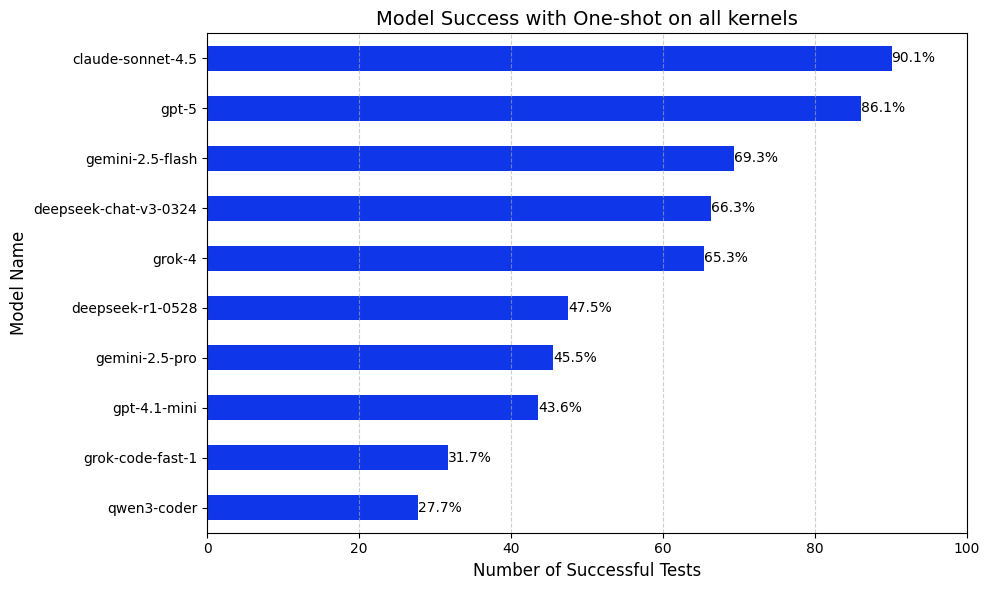

In [26]:
# Generate the Bar chart
plt.figure(figsize=(10,6))

success_rates_norag.plot(kind='barh', color="#0f37e9" )
for index, value in enumerate(success_rates_norag):
    label = f"{value:.1f}%"
    plt.text(value, index, label, va='center') # f' {value}' adds space after the bar
# Formatting and labels
plt.title(f'Model Success with One-shot on all kernels', fontsize=14)
plt.xlabel('Number of Successful Tests', fontsize=12)
plt.xlim(0,100)
plt.ylabel('Model Name', fontsize=12)
# Invert y-axis to put the highest performing model at the top
plt.gca().invert_yaxis() 
plt.grid(axis='x', linestyle='--', alpha=0.6) # Add light grid lines for readability
plt.tight_layout()

# Save and show the plot 
# plt.savefig('HLS_Model_Success_Bar_Chart.png')
plt.show()

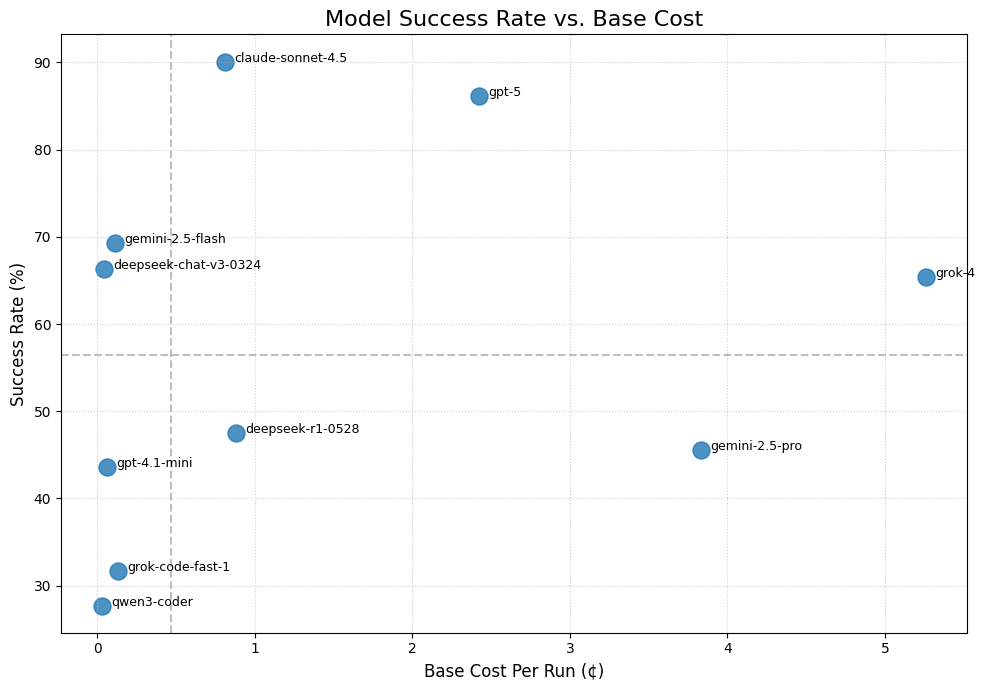

In [27]:
model_costs_data = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'grok-4', 'gemini-2.5-pro', 'claude-sonnet-4.5'],
    'Base_Cost_Per_Run': [0.11, 0.04, 0.88, 0.06, 0.13, 0.03, 2.42, 5.26, 3.83, 0.81]
}
costs_norag_df = pd.DataFrame(model_costs_data).set_index('Model')

combined_norag_df = pd.DataFrame({
    'Success_Rate': success_rates_norag,
    'Cost': costs_norag_df['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

# --- 2. Generate the Scatter Plot ---

plt.figure(figsize=(10, 7))

# Create the scatter plot
plt.scatter(
    combined_norag_df['Cost'], 
    combined_norag_df['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color='#1f77b4'
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---

# Add model labels to the points
for model, row in combined_norag_df.iterrows():
    # Use model name as the label
    plt.annotate(
        model,
        (row['Cost'] + 0.06, row['Success_Rate']), # Offset label slightly to the right
        fontsize=9
    )


median_cost = combined_norag_df['Cost'].median()
median_success = combined_norag_df['Success_Rate'].median()
# Horizontal Line (Median Success)
plt.axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
plt.axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
plt.title('Model Success Rate vs. Base Cost', fontsize=16)
plt.xlabel('Base Cost Per Run (¢)', fontsize=12)
plt.ylabel('Success Rate (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()

# Oneshot Vitis with RAG

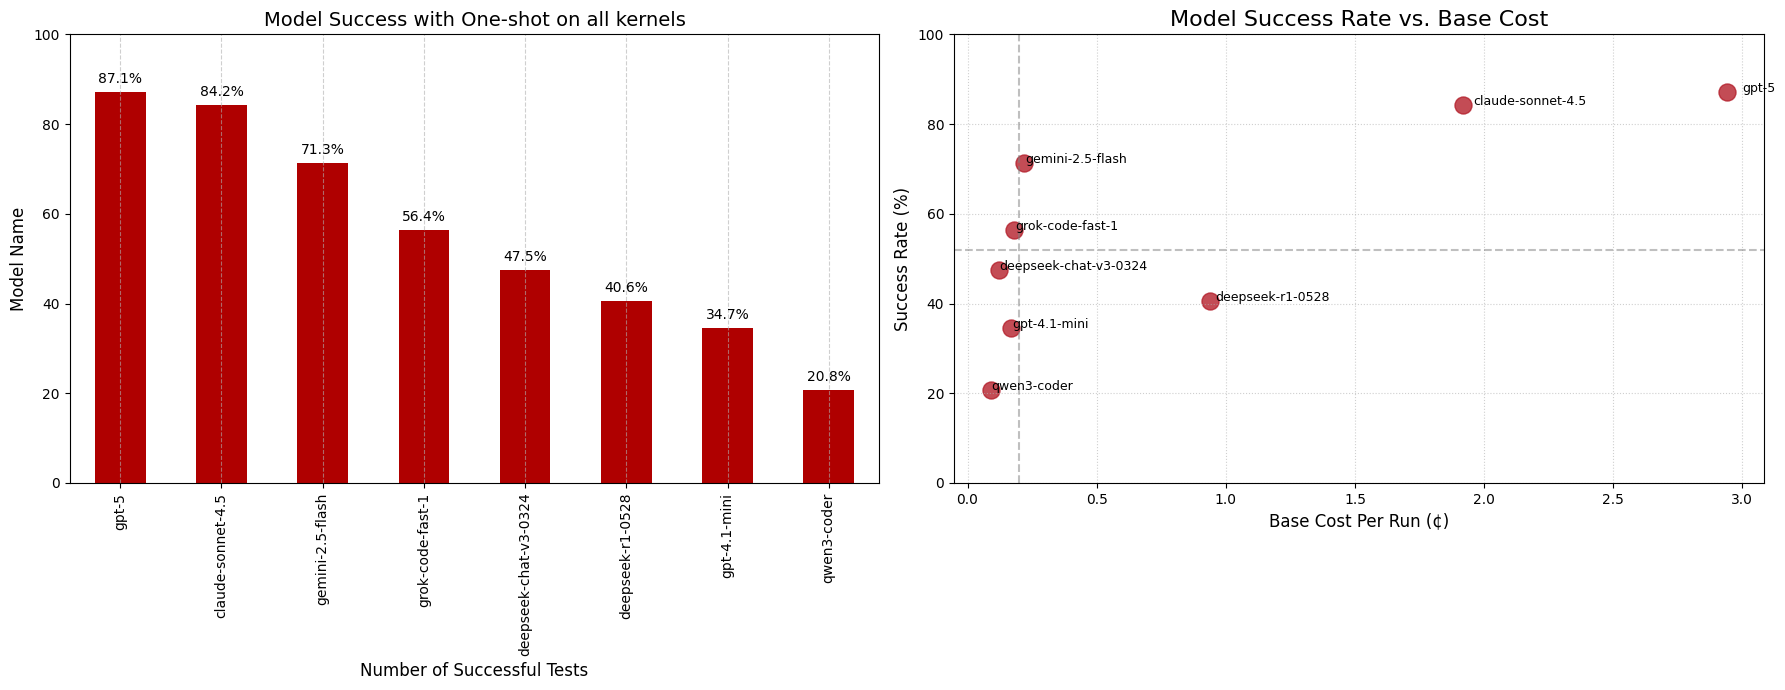

In [ ]:
# Load data
df_oneshot_vitis_cheap = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_rag.csv')
df_oneshot_vitis_expensive = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_rag.csv')
# Calculate and add a column saying success for synthesis
df_oneshot_vitis_comb = pd.concat([df_oneshot_vitis_cheap, df_oneshot_vitis_expensive], ignore_index=True)
df_oneshot_vitis_comb['latency'] = pd.to_numeric(df_oneshot_vitis_comb['latency'], errors='coerce')
df_oneshot_vitis_comb['Success'] = ((df_oneshot_vitis_comb['latency'].notna()) & (df_oneshot_vitis_comb['latency'] > 5)).astype(int)
df_oneshot_vitis_comb['model'] = df_oneshot_vitis_comb['model'].str.split('/').str[-1]

# Calculate the Successes and Group by model
success_counts_unsorted = df_oneshot_vitis_comb.groupby('model')['Success'].sum()
success_counts = df_oneshot_vitis_comb.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_rag = (success_counts / total_tests) * 100
success_rates_unsorted = (success_counts_unsorted / total_tests) * 100

# print(success_rates_rag)

fig, axs = plt.subplots(1, 2, figsize=(18, 7))

# Generate the Bar chart
# plt.figure(figsize=(10,6))

success_rates_rag.plot(kind='bar', color="#af0000", ax=axs[0])
for index, value in enumerate(success_rates_rag):
    label = f"{value:.1f}%"
    axs[0].text(index, value+2, label, ha='center') # f' {value}' adds space after the bar
# Formatting and labels
axs[0].set_title(f'Model Success with One-shot on all kernels', fontsize=14)
axs[0].set_xlabel('Number of Successful Tests', fontsize=12)
axs[0].set_ylim(0,100)
axs[0].set_ylabel('Model Name', fontsize=12)
# Invert y-axis to put the highest performing model at the top
# axs[0].invert_yaxis() 
axs[0].grid(axis='x', linestyle='--', alpha=0.6) # Add light grid lines for readability
# plt.tight_layout()



# END OF BAR PLOT


model_costs_data = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'claude-sonnet-4.5'], # 'grok-4', 'gemini-2.5-pro', ],
    'Base_Cost_Per_Run': [0.22, 0.12, 0.94, 0.17, 0.18, 0.09, 2.94, 1.92]
}
costs_df = pd.DataFrame(model_costs_data).set_index('Model')

combined_df = pd.DataFrame({
    'Success_Rate': success_rates_rag,
    'Cost': costs_df['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

# --- 2. Generate the Scatter Plot ---

# Create the scatter plot
axs[1].scatter(
    combined_df['Cost'], 
    combined_df['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color="#b41f2b"
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---

# Add model labels to the points
for model, row in combined_df.iterrows():
    # Use model name as the label
    axs[1].annotate(
        model,
        (row['Cost'] * 1.02, row['Success_Rate']), # Offset label slightly to the right
        fontsize=9
    )


median_cost = combined_df['Cost'].median()
median_success = combined_df['Success_Rate'].median()
# Horizontal Line (Median Success)
axs[1].axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
axs[1].axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
axs[1].set_title('Model Success Rate vs. Base Cost', fontsize=16)
axs[1].set_xlabel('Base Cost Per Run (¢)', fontsize=12)
axs[1].set_ylabel('Success Rate (%)', fontsize=12)
axs[1].set_ylim(0,100)
axs[1].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()

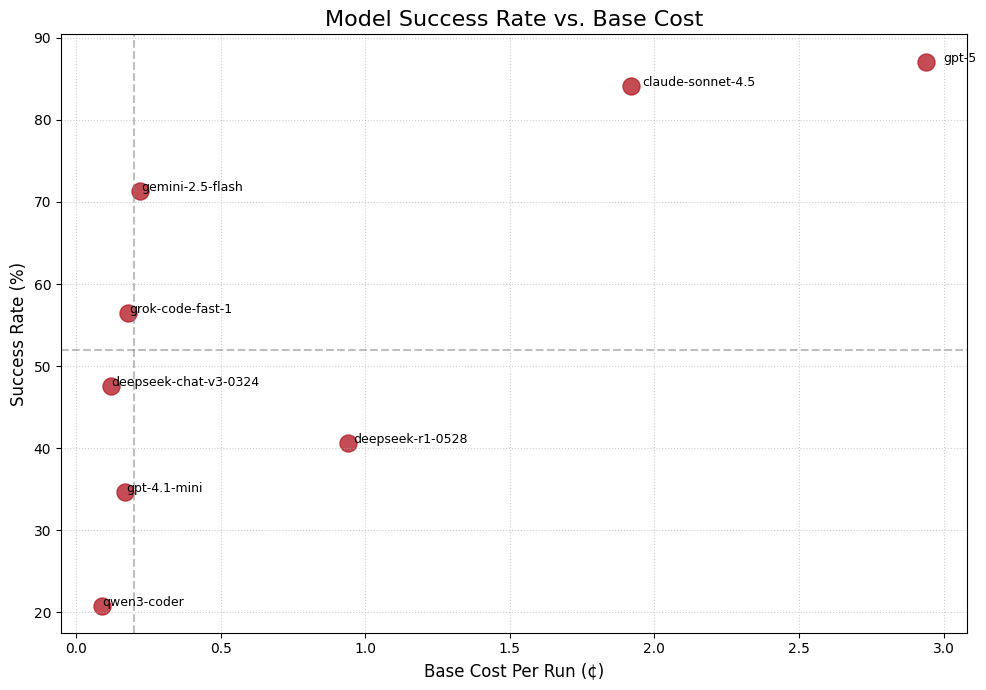

In [29]:
model_costs_data = {
    'Model': ['gemini-2.5-flash', 'deepseek-chat-v3-0324', 'deepseek-r1-0528', 'gpt-4.1-mini', 'grok-code-fast-1',  
              'qwen3-coder', 'gpt-5', 'claude-sonnet-4.5'], # 'grok-4', 'gemini-2.5-pro', ],
    'Base_Cost_Per_Run': [0.22, 0.12, 0.94, 0.17, 0.18, 0.09, 2.94, 1.92]
}
costs_df = pd.DataFrame(model_costs_data).set_index('Model')

combined_rag_df = pd.DataFrame({
    'Success_Rate': success_rates_rag,
    'Cost': costs_df['Base_Cost_Per_Run'] # Assuming this column name in your data
}).dropna() # Drop any model that might be missing one of the values

# --- 2. Generate the Scatter Plot ---

plt.figure(figsize=(10, 7))

# Create the scatter plot
plt.scatter(
    combined_rag_df['Cost'], 
    combined_rag_df['Success_Rate'], 
    s=150,  # Size of the points
    alpha=0.8,
    color="#b41f2b"
)

# --- 3. Labeling and Formatting for Cost-Effectiveness ---

# Add model labels to the points
for model, row in combined_rag_df.iterrows():
    # Use model name as the label
    plt.annotate(
        model,
        (row['Cost'] * 1.02, row['Success_Rate']), # Offset label slightly to the right
        fontsize=9
    )


median_cost = combined_rag_df['Cost'].median()
median_success = combined_rag_df['Success_Rate'].median()
# Horizontal Line (Median Success)
plt.axhline(median_success, color='gray', linestyle='--', alpha=0.5)
# Vertical Line (Median Cost)
plt.axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
plt.title('Model Success Rate vs. Base Cost', fontsize=16)
plt.xlabel('Base Cost Per Run (¢)', fontsize=12)
plt.ylabel('Success Rate (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
# plt.savefig('Model_Cost_Effectiveness_Scatter_Plot.png')
plt.show()

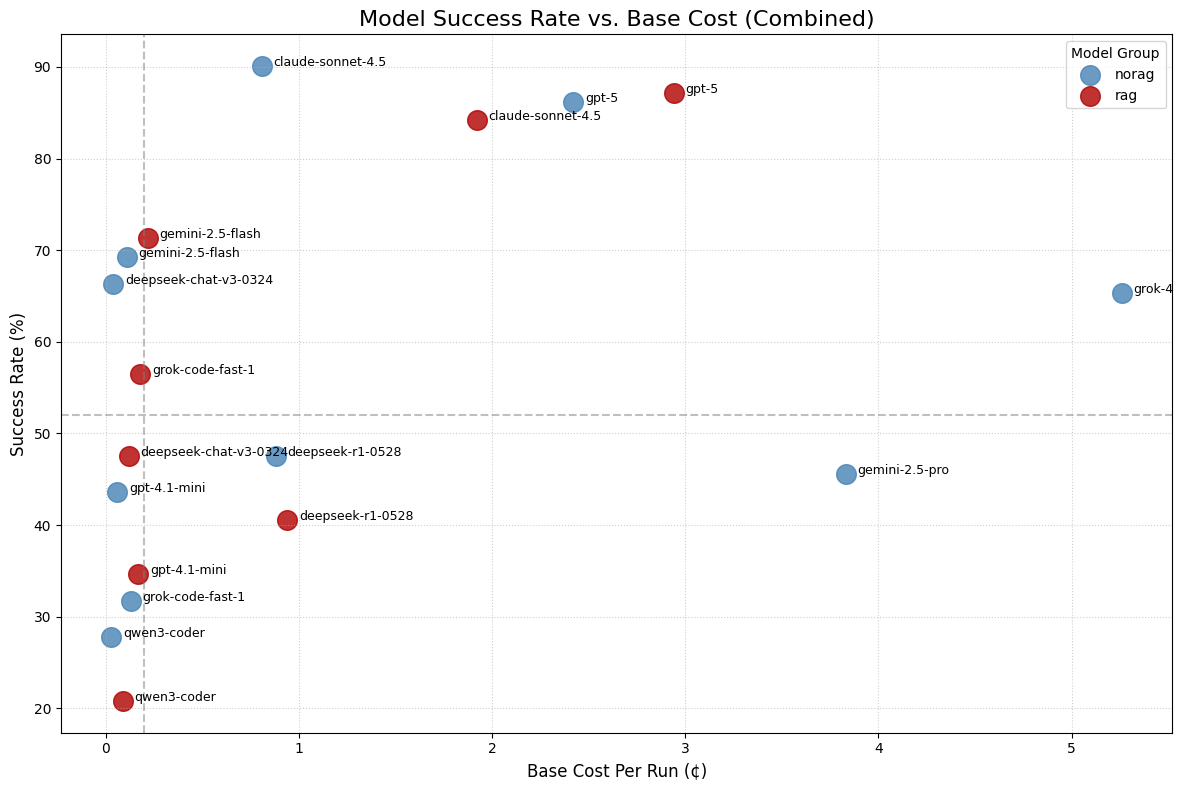

In [30]:
#Combine the two scatter plots

combined_norag_df['Group'] = "norag"
combined_rag_df['Group'] = "rag"

combined_df = pd.concat([combined_norag_df, combined_rag_df], ignore_index=False)
# print(combined_df)
# --- Generate the Overlapped Scatter Plot ---
plt.figure(figsize=(12, 8))

# Define colors for the groups
colors = {'rag': '#af0000', 'norag': 'steelblue'}

# Plot each group separately to assign different colors and labels
for name, group in combined_df.groupby('Group'):
    plt.scatter(
        group['Cost'],
        group['Success_Rate'],
        s=200,  # Size of the points
        alpha=0.8,
        color=colors[name],
        label=name # Label for the legend
    )

# Add model labels to the points
for model, row in combined_df.iterrows():
    plt.annotate(
        model,
        (row['Cost'] + 0.06, row['Success_Rate']), # Offset label slightly
        fontsize=9
    )
# Add median lines
median_cost = combined_df['Cost'].median()
median_success = combined_df['Success_Rate'].median()
plt.axhline(median_success, color='gray', linestyle='--', alpha=0.5)
plt.axvline(median_cost, color='gray', linestyle='--', alpha=0.5)

# Final Plot Aesthetics
plt.title('Model Success Rate vs. Base Cost (Combined)', fontsize=16)
plt.xlabel('Base Cost Per Run (¢)', fontsize=12)
plt.ylabel('Success Rate (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(title="Model Group") # Show legend to differentiate groups
plt.tight_layout()

plt.show()


(274, 17)
(289, 17)


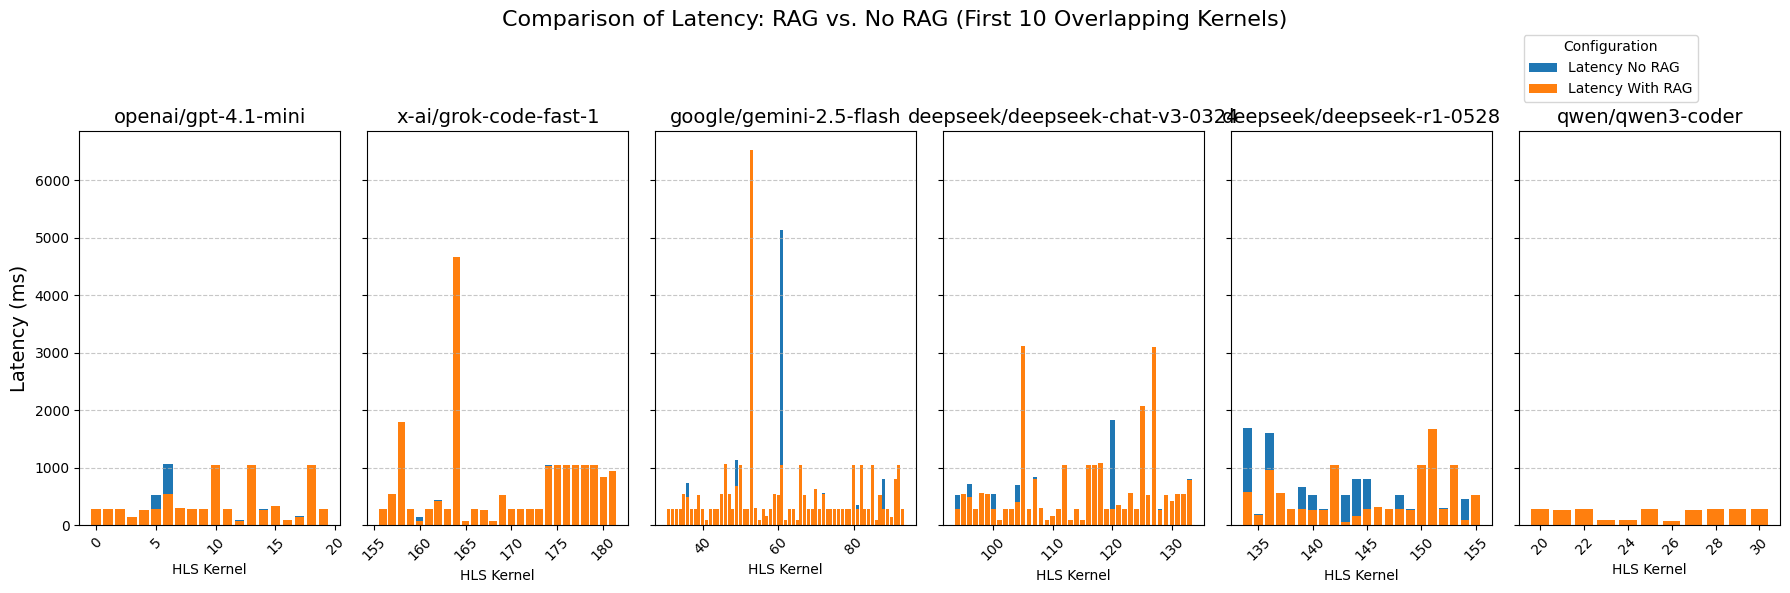

In [31]:
# Displaying the latencies in different ways
# Load data
df_rag = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_rag.csv')
df_norag = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_norag.csv')

df_rag['latency'] = pd.to_numeric(df_rag['latency'], errors='coerce')
df_norag['latency'] = pd.to_numeric(df_norag['latency'], errors='coerce')

mask_rag = ((df_rag['latency'].notna()) & (df_rag['latency'] > 5))
# print(mask_rag)
df_successes_rag = df_rag[mask_rag]
print(df_successes_rag.shape)

mask_norag = ((df_norag['latency'].notna()) & (df_norag['latency'] > 5))
# print(mask_rag)
df_success_norag = df_norag[mask_norag]
print(df_success_norag.shape)

df_combined = pd.merge(
    df_successes_rag,          # The left DataFrame (RAG successes)
    df_success_norag,        # The right DataFrame (No-RAG successes)
    on=['model', 'kernel'],    # The columns to match on (the common key)
    how='inner',               # Specifies that only rows present in BOTH DataFrames are kept
    suffixes=('_rag', '_norag') # Appends suffixes to distinguish columns with the same name (like 'latency')
)

# print(df_combined)

colors = {
    'Latency No RAG': '#1f77b4',  # Blue (Back, larger bar)
    'Latency With RAG': '#ff7f0e' # Orange (Front, smaller bar)
}

models = [
    'openai/gpt-4.1-mini',
    'x-ai/grok-code-fast-1',
    'google/gemini-2.5-flash',
    'deepseek/deepseek-chat-v3-0324',
    'deepseek/deepseek-r1-0528',
    'qwen/qwen3-coder'
    ]
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(18, 6), sharey=True)
fig.suptitle('Comparison of Latency: RAG vs. No RAG (First 10 Overlapping Kernels)',
             fontsize=16)

# Iterate through models to create subplots
for i, model in enumerate(models):
    ax = axes[i]
    
    # Select the data for the current model
    # Note: df_pivoted is created in the execution step to make data easy to access
    kernel_data = df_combined[df_combined['model'] == model]
    kernel_data = kernel_data[['model', 'latency_norag', 'latency_rag']]

    kernel_data.columns = ['Model', 'Latency No RAG', 'Latency With RAG']
    kernels = kernel_data.index
    # print(kernel_data)
    # 1. Base Bar: Latency No RAG (Blue - the larger value, should be in the back)
    ax.bar(
        kernels,
        kernel_data['Latency No RAG'],
        label='Latency No RAG',
        color=colors['Latency No RAG']
    )

    # 2. Overlapping Bar: Latency With RAG (Orange - the smaller value, visually "in front")
    # This bar is plotted over the first one. Since it's shorter, it reveals the difference.
    ax.bar(
        kernels,
        kernel_data['Latency With RAG'],
        label='Latency With RAG',
        color=colors['Latency With RAG']
    )

    # Styling and labels
    ax.set_title(model, fontsize=14)
    ax.set_xlabel('HLS Kernel')
    ax.tick_params(axis='x', rotation=45) 
    ax.grid(axis='y', linestyle='--', alpha=0.7)

axes[0].set_ylabel('Latency (ms)', fontsize=14)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.95, 0.95), ncol=1, title="Configuration")

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

# One Shot Vitis with No RAG

## Comparing the different runs with eachother

/tmp/ipykernel_2460507/2393448495.py:92: UserWarning: 
The palette list has fewer values (2) than needed (5) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(


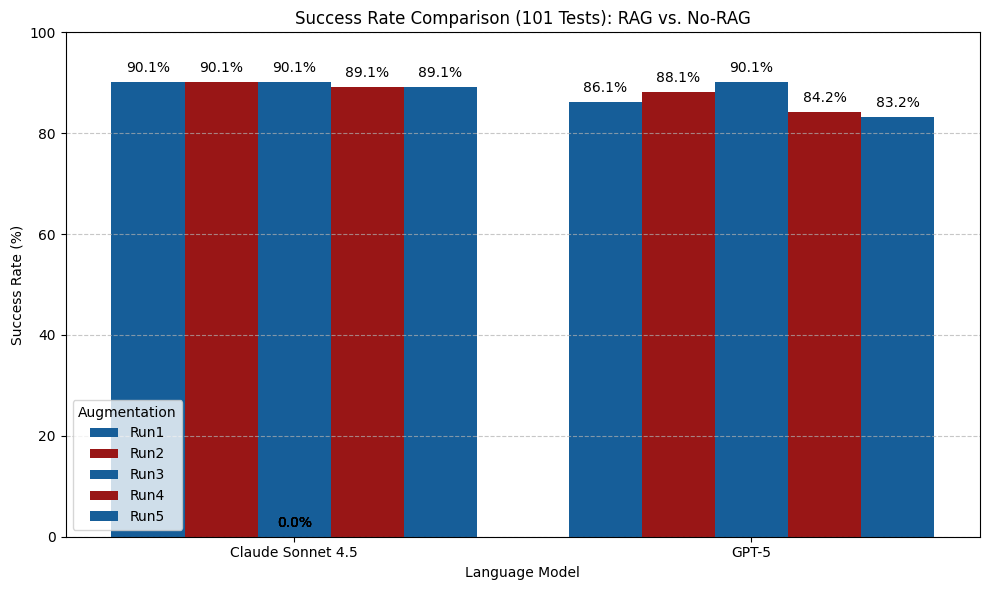

In [32]:
df_expensive_norag1 = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_norag.csv')
df_expensive_norag2 = pd.read_csv('final_data/run2/vitis_oneshot_expensive_models_norag.csv')
df_expensive_norag3 = pd.read_csv('final_data/run3/vitis_oneshot_expensive_models_norag.csv')
df_expensive_norag4 = pd.read_csv('final_data/run4/vitis_oneshot_expensive_models_norag.csv')
df_expensive_norag5 = pd.read_csv('final_data/run5/vitis_oneshot_expensive_models_norag.csv')


df_expensive_norag1 = df_expensive_norag1[df_expensive_norag1['model'].isin({"openai/gpt-5", "anthropic/claude-sonnet-4.5"})].copy()
df_expensive_norag1.loc[:, 'israg'] = True
# print(df_claude_gpt5)
df_expensive_norag2 = df_expensive_norag2[df_expensive_norag2['model'].isin({"openai/gpt-5", "anthropic/claude-sonnet-4.5"})].copy()
df_expensive_norag2.loc[:, 'israg'] = True
# print(df_claude_gpt5_rag)
df_expensive_norag3.loc[:, 'israg'] = True
df_expensive_norag4.loc[:, 'israg'] = True
df_expensive_norag5.loc[:, 'israg'] = True


df_expensive_norag1['latency'] = pd.to_numeric(df_expensive_norag1['latency'], errors='coerce')
df_expensive_norag1['Success'] = ((df_expensive_norag1['latency'].notna()) & (df_expensive_norag1['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_expensive_norag1.groupby('model')['Success'].sum()
success_counts = df_expensive_norag1.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag1 = (success_counts / total_tests) * 100
success_rates_unsorted_norag = (success_counts_unsorted / total_tests) * 100

df_expensive_norag2['latency'] = pd.to_numeric(df_expensive_norag2['latency'], errors='coerce')
df_expensive_norag2['Success'] = ((df_expensive_norag2['latency'].notna()) & (df_expensive_norag2['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_expensive_norag2.groupby('model')['Success'].sum()
success_counts = df_expensive_norag2.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag2 = (success_counts / total_tests) * 100
success_rates_unsorted_rag = (success_counts_unsorted / total_tests) * 100

df_expensive_norag3['latency'] = pd.to_numeric(df_expensive_norag3['latency'], errors='coerce')
df_expensive_norag3['Success'] = ((df_expensive_norag3['latency'].notna()) & (df_expensive_norag3['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_expensive_norag3.groupby('model')['Success'].sum()
success_counts = df_expensive_norag3.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag3 = (success_counts / total_tests) * 100
success_rates_unsorted_rag = (success_counts_unsorted / total_tests) * 100

df_expensive_norag4['latency'] = pd.to_numeric(df_expensive_norag4['latency'], errors='coerce')
df_expensive_norag4['Success'] = ((df_expensive_norag4['latency'].notna()) & (df_expensive_norag4['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_expensive_norag4.groupby('model')['Success'].sum()
success_counts = df_expensive_norag4.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag4 = (success_counts / total_tests) * 100
success_rates_unsorted_rag = (success_counts_unsorted / total_tests) * 100

df_expensive_norag5['latency'] = pd.to_numeric(df_expensive_norag5['latency'], errors='coerce')
df_expensive_norag5['Success'] = ((df_expensive_norag5['latency'].notna()) & (df_expensive_norag5['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_expensive_norag5.groupby('model')['Success'].sum()
success_counts = df_expensive_norag5.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag5 = (success_counts / total_tests) * 100
success_rates_unsorted_rag = (success_counts_unsorted / total_tests) * 100


import seaborn as sns
df_plot = pd.DataFrame({
    'Run1': success_rates_norag1,
    'Run2': success_rates_norag2,
    'Run3': success_rates_norag3,
    'Run4': success_rates_norag4,
    'Run5': success_rates_norag5
})

# 2. Reformat the DataFrame for a grouped bar chart (using index as 'Model')
df_plot = df_plot.reset_index().rename(columns={'model': 'Model'})
df_plot_melted = df_plot.melt(
    id_vars='Model', 
    var_name='RAG_Status', 
    value_name='Success_Rate'
)

# Rename models for better display
model_names = {
    'openai/gpt-5': 'GPT-5', 
    'anthropic/claude-sonnet-4.5': 'Claude Sonnet 4.5'
}
df_plot_melted['Model'] = df_plot_melted['Model'].replace(model_names)

# --- Visualization ---

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Model', 
    y='Success_Rate', 
    hue='RAG_Status', 
    data=df_plot_melted, 
    palette=["#0060af", "#af0000"]
)

# Add title and labels
plt.title(f'Success Rate Comparison ({total_tests} Tests): RAG vs. No-RAG')
plt.ylabel('Success Rate (%)')
plt.xlabel('Language Model')
plt.ylim(0, 100) # Ensure the Y-axis goes up to 100%

# Add text labels on top of the bars
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():.1f}%', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', 
                       va='bottom',
                       fontsize=10,
                       color='black',
                       xytext=(0, 5), 
                       textcoords='offset points')

plt.legend(title='Augmentation')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()



(173, 17)
(178, 17)


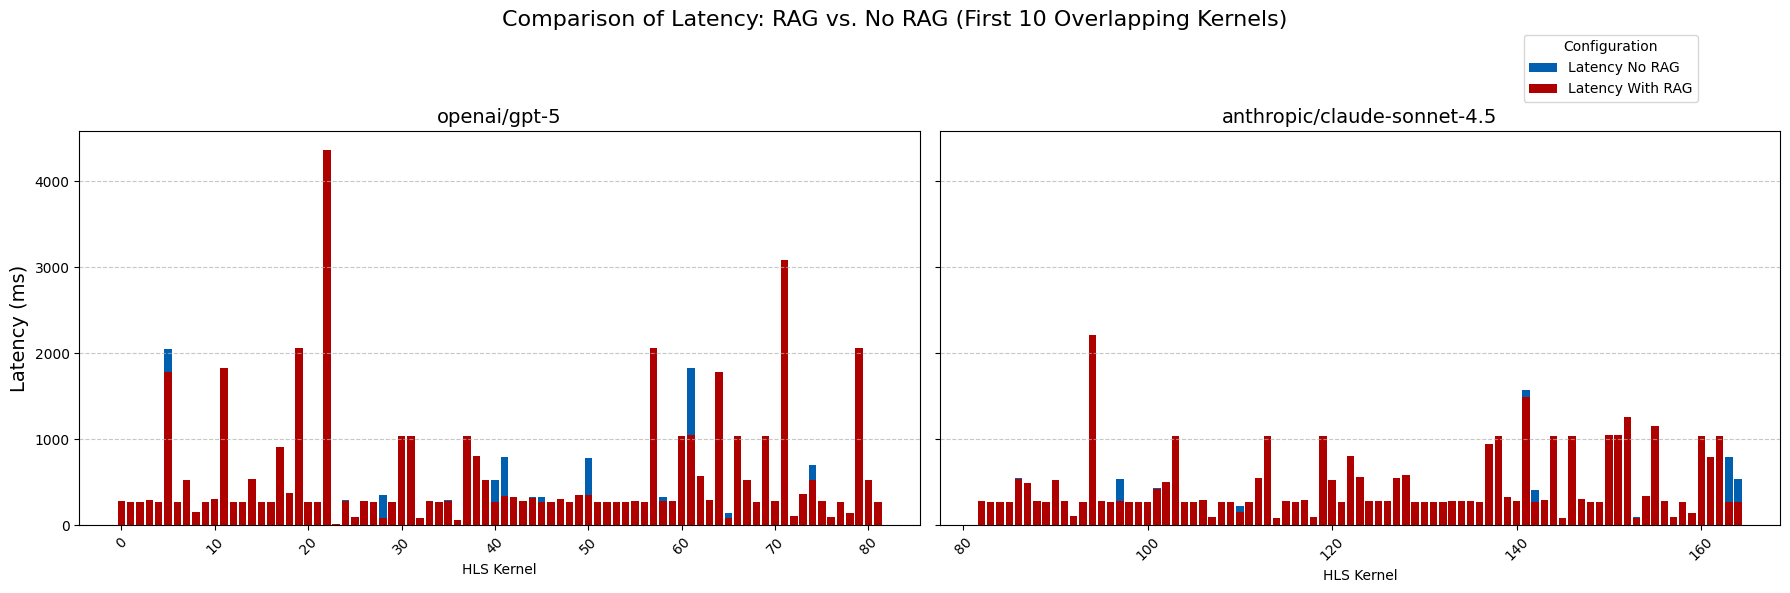

In [33]:
# Displaying the latencies in different ways
# Load data
df_rag = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_rag.csv')
df_norag = pd.read_csv('final_data/run1/vitis_oneshot_expensive_models_norag.csv')
df_rag = df_rag[df_rag['model'].isin({"openai/gpt-5", "anthropic/claude-sonnet-4.5"})].copy()
df_norag = df_norag[df_norag['model'].isin({"openai/gpt-5", "anthropic/claude-sonnet-4.5"})].copy()


df_rag['latency'] = pd.to_numeric(df_rag['latency'], errors='coerce')
df_norag['latency'] = pd.to_numeric(df_norag['latency'], errors='coerce')

mask_rag = ((df_rag['latency'].notna()) & (df_rag['latency'] > 5))
# print(mask_rag)
df_successes_rag = df_rag[mask_rag]
print(df_successes_rag.shape)

mask_norag = ((df_norag['latency'].notna()) & (df_norag['latency'] > 5))
# print(mask_rag)
df_success_norag = df_norag[mask_norag]
print(df_success_norag.shape)

df_combined = pd.merge(
    df_successes_rag,          # The left DataFrame (RAG successes)
    df_success_norag,        # The right DataFrame (No-RAG successes)
    on=['model', 'kernel'],    # The columns to match on (the common key)
    how='inner',               # Specifies that only rows present in BOTH DataFrames are kept
    suffixes=('_rag', '_norag') # Appends suffixes to distinguish columns with the same name (like 'latency')
)

# print(df_combined)

colors = {
    'Latency No RAG': '#0060af', 
    'Latency With RAG': '#af0000' 
}

models = [
    'openai/gpt-5',
    'anthropic/claude-sonnet-4.5'
    ]
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(18, 6), sharey=True)
fig.suptitle('Comparison of Latency: RAG vs. No RAG (First 10 Overlapping Kernels)',
             fontsize=16)

# Iterate through models to create subplots
for i, model in enumerate(models):
    ax = axes[i]
    
    # Select the data for the current model
    # Note: df_pivoted is created in the execution step to make data easy to access
    kernel_data = df_combined[df_combined['model'] == model]
    kernel_data = kernel_data[['model', 'latency_norag', 'latency_rag']]

    kernel_data.columns = ['Model', 'Latency No RAG', 'Latency With RAG']
    kernels = kernel_data.index
    # print(kernel_data)
    # 1. Base Bar: Latency No RAG (Blue - the larger value, should be in the back)
    ax.bar(
        kernels,
        kernel_data['Latency No RAG'],
        label='Latency No RAG',
        color=colors['Latency No RAG']
    )

    # 2. Overlapping Bar: Latency With RAG (Orange - the smaller value, visually "in front")
    # This bar is plotted over the first one. Since it's shorter, it reveals the difference.
    ax.bar(
        kernels,
        kernel_data['Latency With RAG'],
        label='Latency With RAG',
        color=colors['Latency With RAG']
    )

    # Styling and labels
    ax.set_title(model, fontsize=14)
    ax.set_xlabel('HLS Kernel')
    ax.tick_params(axis='x', rotation=45) 
    ax.grid(axis='y', linestyle='--', alpha=0.7)

axes[0].set_ylabel('Latency (ms)', fontsize=14)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.95, 0.95), ncol=1, title="Configuration")

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

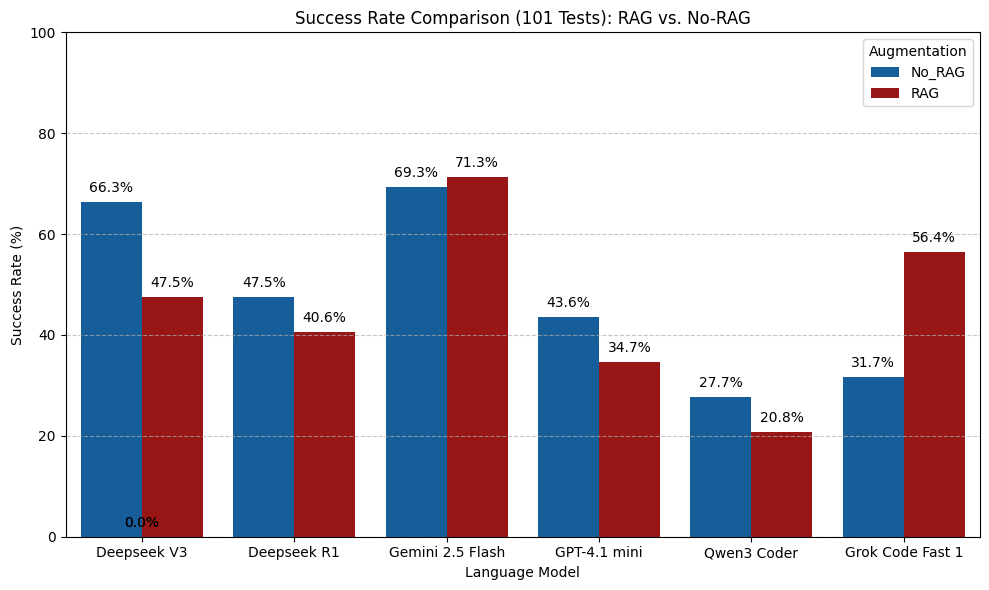

In [34]:
df_cheap_rag = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_rag.csv')
df_cheap_norag = pd.read_csv('final_data/run1/vitis_oneshot_cheap_models_norag.csv')

df_claude_gpt5_norag = df_cheap_norag[df_cheap_norag['model'].isin({"openai/gpt-4.1-mini","x-ai/grok-code-fast-1","google/gemini-2.5-flash","deepseek/deepseek-chat-v3-0324","deepseek/deepseek-r1-0528","qwen/qwen3-coder"})].copy()
df_claude_gpt5_norag.loc[:, 'israg'] = False
# print(df_claude_gpt5)
df_claude_gpt5_rag = df_cheap_rag[df_cheap_rag['model'].isin({"openai/gpt-4.1-mini","x-ai/grok-code-fast-1","google/gemini-2.5-flash","deepseek/deepseek-chat-v3-0324","deepseek/deepseek-r1-0528","qwen/qwen3-coder"})].copy()
df_claude_gpt5_rag.loc[:, 'israg'] = True
# print(df_claude_gpt5_rag)

df_claude_gpt5_norag['latency'] = pd.to_numeric(df_claude_gpt5_norag['latency'], errors='coerce')
df_claude_gpt5_norag['Success'] = ((df_claude_gpt5_norag['latency'].notna()) & (df_claude_gpt5_norag['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_claude_gpt5_norag.groupby('model')['Success'].sum()
success_counts = df_claude_gpt5_norag.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag = (success_counts / total_tests) * 100
success_rates_unsorted_norag = (success_counts_unsorted / total_tests) * 100

df_claude_gpt5_rag['latency'] = pd.to_numeric(df_claude_gpt5_rag['latency'], errors='coerce')
df_claude_gpt5_rag['Success'] = ((df_claude_gpt5_rag['latency'].notna()) & (df_claude_gpt5_rag['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_claude_gpt5_rag.groupby('model')['Success'].sum()
success_counts = df_claude_gpt5_rag.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_rag = (success_counts / total_tests) * 100
success_rates_unsorted_rag = (success_counts_unsorted / total_tests) * 100

import seaborn as sns
df_plot = pd.DataFrame({
    'No_RAG': success_rates_norag,
    'RAG': success_rates_rag
})

# 2. Reformat the DataFrame for a grouped bar chart (using index as 'Model')
df_plot = df_plot.reset_index().rename(columns={'model': 'Model'})
df_plot_melted = df_plot.melt(
    id_vars='Model', 
    var_name='RAG_Status', 
    value_name='Success_Rate'
)

# Rename models for better display
model_names = {
    "openai/gpt-4.1-mini": "GPT-4.1 mini",
    "x-ai/grok-code-fast-1": "Grok Code Fast 1",
    "google/gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek/deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek/deepseek-r1-0528": "Deepseek R1",
    "qwen/qwen3-coder": "Qwen3 Coder"
}

df_plot_melted['Model'] = df_plot_melted['Model'].replace(model_names)

# --- Visualization ---

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Model', 
    y='Success_Rate', 
    hue='RAG_Status', 
    data=df_plot_melted, 
    palette=["#0060af", "#af0000"] # Blue for No RAG, Green for RAG
)

# Add title and labels
plt.title(f'Success Rate Comparison ({total_tests} Tests): RAG vs. No-RAG')
plt.ylabel('Success Rate (%)')
plt.xlabel('Language Model')
plt.ylim(0, 100) # Ensure the Y-axis goes up to 100%

# Add text labels on top of the bars
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():.1f}%', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', 
                       va='bottom',
                       fontsize=10,
                       color='black',
                       xytext=(0, 5), 
                       textcoords='offset points')

plt.legend(title='Augmentation')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


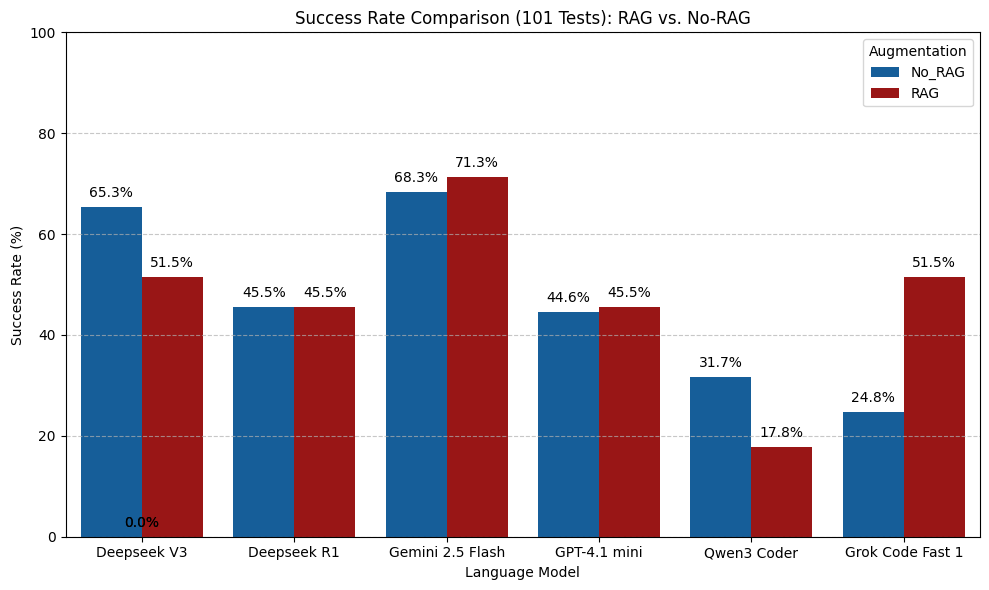

In [35]:
df_cheap_rag = pd.read_csv('final_data/run2/vitis_oneshot_cheap_models_rag.csv')
df_cheap_norag = pd.read_csv('final_data/run2/vitis_oneshot_cheap_models_norag.csv')

df_claude_gpt5_norag = df_cheap_norag[df_cheap_norag['model'].isin({"openai/gpt-4.1-mini","x-ai/grok-code-fast-1","google/gemini-2.5-flash","deepseek/deepseek-chat-v3-0324","deepseek/deepseek-r1-0528","qwen/qwen3-coder"})].copy()
df_claude_gpt5_norag.loc[:, 'israg'] = False
# print(df_claude_gpt5)
df_claude_gpt5_rag = df_cheap_rag[df_cheap_rag['model'].isin({"openai/gpt-4.1-mini","x-ai/grok-code-fast-1","google/gemini-2.5-flash","deepseek/deepseek-chat-v3-0324","deepseek/deepseek-r1-0528","qwen/qwen3-coder"})].copy()
df_claude_gpt5_rag.loc[:, 'israg'] = True
# print(df_claude_gpt5_rag)

df_claude_gpt5_norag['latency'] = pd.to_numeric(df_claude_gpt5_norag['latency'], errors='coerce')
df_claude_gpt5_norag['Success'] = ((df_claude_gpt5_norag['latency'].notna()) & (df_claude_gpt5_norag['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_claude_gpt5_norag.groupby('model')['Success'].sum()
success_counts = df_claude_gpt5_norag.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_norag = (success_counts / total_tests) * 100
success_rates_unsorted_norag = (success_counts_unsorted / total_tests) * 100

df_claude_gpt5_rag['latency'] = pd.to_numeric(df_claude_gpt5_rag['latency'], errors='coerce')
df_claude_gpt5_rag['Success'] = ((df_claude_gpt5_rag['latency'].notna()) & (df_claude_gpt5_rag['latency'] > 5)).astype(int)
# print(df_claude_gpt5_norag)
success_counts_unsorted = df_claude_gpt5_rag.groupby('model')['Success'].sum()
success_counts = df_claude_gpt5_rag.groupby('model')['Success'].sum().sort_values(ascending=False)
total_tests = 101
success_rates_rag = (success_counts / total_tests) * 100
success_rates_unsorted_rag = (success_counts_unsorted / total_tests) * 100

import seaborn as sns
df_plot = pd.DataFrame({
    'No_RAG': success_rates_norag,
    'RAG': success_rates_rag
})

# 2. Reformat the DataFrame for a grouped bar chart (using index as 'Model')
df_plot = df_plot.reset_index().rename(columns={'model': 'Model'})
df_plot_melted = df_plot.melt(
    id_vars='Model', 
    var_name='RAG_Status', 
    value_name='Success_Rate'
)

# Rename models for better display
model_names = {
    "openai/gpt-4.1-mini": "GPT-4.1 mini",
    "x-ai/grok-code-fast-1": "Grok Code Fast 1",
    "google/gemini-2.5-flash": "Gemini 2.5 Flash",
    "deepseek/deepseek-chat-v3-0324": "Deepseek V3",
    "deepseek/deepseek-r1-0528": "Deepseek R1",
    "qwen/qwen3-coder": "Qwen3 Coder"
}

df_plot_melted['Model'] = df_plot_melted['Model'].replace(model_names)

# --- Visualization ---

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Model', 
    y='Success_Rate', 
    hue='RAG_Status', 
    data=df_plot_melted, 
    palette=["#0060af", "#af0000"] # Blue for No RAG, Green for RAG
)

# Add title and labels
plt.title(f'Success Rate Comparison ({total_tests} Tests): RAG vs. No-RAG')
plt.ylabel('Success Rate (%)')
plt.xlabel('Language Model')
plt.ylim(0, 100) # Ensure the Y-axis goes up to 100%

# Add text labels on top of the bars
for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():.1f}%', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', 
                       va='bottom',
                       fontsize=10,
                       color='black',
                       xytext=(0, 5), 
                       textcoords='offset points')

plt.legend(title='Augmentation')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
